# ChuvaSegura – Machine Learning: vai cair chuva forte nas próximas 3 horas?

**Global Solution FIAP 2026.2 · CitizenTech · Inteligência Artificial & Machine Learning**

| | |
|---|---|
| **CitizenTech** | ChuvaSegura |
| **Cidade e bairro** | São Paulo – Ipiranga |
| **Cidadão** | Morador de rua com histórico de alagamento (inclui idosos e pessoas com mobilidade reduzida) |
| **Integrantes** | _[NOMES E RMs]_ |

## 1. O problema vira uma pergunta de Machine Learning

No ChuvaSegura, o sensor de nível mede a água **quando ela já está subindo**. Para o morador ganhar tempo, precisamos de um aviso **antes** da chuva.

**Pergunta de ML (classificação binária):**
> Com o que a estação meteorológica mede **agora** e nas **últimas horas** (chuva, pressão, temperatura, umidade, vento), vai cair **chuva forte** nas **próximas 3 horas**?

- **Alvo (`alvo`)**: `1` se a chuva acumulada nas próximas 3 horas for **≥ limiar** (definido na configuração abaixo); `0` caso contrário.
- **Por que isso ajuda o cidadão?** A saída do modelo é uma **probabilidade**. Ela pode reforçar o risco calculado pela API de monitoramento e dar ao morador (principalmente quem precisa de mais tempo para agir) um aviso preventivo.

## 2. Dados reais e públicos

- **Fonte:** INMET – Instituto Nacional de Meteorologia, *Dados Históricos* (observações horárias das estações automáticas). Página: https://portal.inmet.gov.br/dadoshistoricos
- **Estação:** `A701` – São Paulo (Mirante de Santana).
- **Atenção:** a estação **não fica no Ipiranga**; ela representa a **cidade** de São Paulo. Isso é uma limitação, e será discutida na conclusão.
- Passo a passo do download, período e variáveis: veja `dados/README.md`.
- **Não há nenhum dado simulado neste notebook.**

In [1]:
from pathlib import Path
import io
import json
import re
import unicodedata
import warnings
import zipfile

import joblib
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from sklearn.base import clone
from sklearn.dummy import DummyClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.impute import SimpleImputer
from sklearn.inspection import permutation_importance
from sklearn.metrics import (
    average_precision_score,
    confusion_matrix,
    f1_score,
    fbeta_score,
    precision_recall_curve,
    precision_score,
    recall_score,
    roc_auc_score,
)
from sklearn.model_selection import RandomizedSearchCV, TimeSeriesSplit
from sklearn.pipeline import Pipeline

warnings.filterwarnings("ignore", category=FutureWarning)
pd.set_option("display.max_columns", 50)
pd.set_option("display.width", 160)
plt.rcParams["figure.dpi"] = 110

## 3. Configuração

Tudo o que a equipe pode ajustar fica aqui. **Justifiquem no relatório** o limiar de chuva forte (cite uma fonte, como a classificação de intensidade de chuva do INMET/CGE ou da OMM; confirmem o valor na fonte que escolherem) e o período escolhido.

In [2]:
ESTACAO = "A701"                 # INMET: São Paulo - Mirante de Santana
DADOS_DIR = Path("dados/inmet")  # coloque aqui os ZIPs anuais do INMET (ou os CSVs extraídos)
SAIDA_DIR = Path("resultados")   # gráficos e métricas
MODELO_DIR = Path("modelo")      # modelo treinado

HORIZONTE_H = 3        # olhamos quantas horas à frente
LIMIAR_MM = 10.0       # chuva acumulada no horizonte (mm) a partir da qual consideramos "chuva forte"
ANO_TESTE = None       # None = usa o último ano COMPLETO (12 meses) como teste
SEED = 42
N_ITER = 12            # combinações de hiperparâmetros testadas (mínimo exigido: 10)
N_SPLITS = 5           # dobras da validação cruzada temporal (somente dentro do treino)

SAIDA_DIR.mkdir(exist_ok=True)
MODELO_DIR.mkdir(exist_ok=True)

## 4. Carregando os dados do INMET

Os arquivos do INMET têm um cabeçalho com 8 linhas de metadados, separador `;`, decimal com vírgula e `-9999` para valores ausentes. O formato de data e hora varia entre os anos, então o leitor abaixo é **tolerante**: procura as colunas pelo nome (sem acento), aceita ZIP ou CSV e converte tudo para o mesmo padrão.

In [3]:
MAPA_COLUNAS = {
    "chuva_mm": ["precipitacao total"],
    "pressao_hpa": ["pressao atmosferica ao nivel da estacao"],
    "temp_c": ["temperatura do ar"],
    "orvalho_c": ["temperatura do ponto de orvalho"],
    "umidade_pct": ["umidade relativa do ar"],
    "vento_ms": ["vento, velocidade"],
    "rajada_ms": ["vento, rajada"],
    "radiacao_kj": ["radiacao global"],
}


def normalizar(texto) -> str:
    """Minúsculas, sem acentos e sem espaços repetidos (para comparar nomes de colunas)."""
    texto = unicodedata.normalize("NFKD", str(texto)).encode("ascii", "ignore").decode("ascii")
    return re.sub(r"\s+", " ", texto).strip().lower()


def decodificar(conteudo: bytes) -> str:
    try:
        return conteudo.decode("utf-8-sig")
    except UnicodeDecodeError:
        return conteudo.decode("latin-1")


def ler_csv_inmet(conteudo: bytes) -> pd.DataFrame:
    """Lê um CSV de estação do INMET e devolve colunas padronizadas (horário em UTC)."""
    linhas = decodificar(conteudo).splitlines()
    inicio = next(i for i, linha in enumerate(linhas) if normalizar(linha).startswith("data;"))
    tabela = pd.read_csv(io.StringIO("\n".join(linhas[inicio:])), sep=";", dtype=str, index_col=False)

    col_data = next(c for c in tabela.columns if normalizar(c) == "data")
    col_hora = next(c for c in tabela.columns if normalizar(c).startswith("hora"))

    # Datas: "2019/01/01" ou "2023-01-01". Horas: "0000 UTC" ou "00:00 UTC" -> pegamos só a hora cheia.
    datas = pd.to_datetime(
        tabela[col_data].astype(str).str.strip().str.replace("/", "-", regex=False),
        format="%Y-%m-%d",
        errors="coerce",
    )
    horas = pd.to_numeric(
        tabela[col_hora].astype(str).str.replace(r"\D", "", regex=True).str.zfill(4).str[:2],
        errors="coerce",
    ).where(tabela[col_hora].notna())

    saida = pd.DataFrame({"instante_utc": datas + pd.to_timedelta(horas, unit="h")})

    for nome, palavras in MAPA_COLUNAS.items():
        coluna = next((c for c in tabela.columns if any(p in normalizar(c) for p in palavras)), None)
        if coluna is None:
            print(f"  aviso: coluna de '{nome}' não encontrada; ficará vazia")
            saida[nome] = np.nan
            continue
        valores = pd.to_numeric(
            tabela[coluna].astype(str).str.replace(",", ".", regex=False).str.strip(), errors="coerce"
        )
        saida[nome] = valores.where(valores > -9000)  # -9999 = ausente

    return saida.dropna(subset=["instante_utc"])


def carregar_estacao(pasta: Path, estacao: str) -> pd.DataFrame:
    partes = []
    for arquivo in sorted(pasta.rglob("*")):
        sufixo = arquivo.suffix.lower()
        if sufixo == ".zip":
            with zipfile.ZipFile(arquivo) as zf:
                for nome in zf.namelist():
                    if nome.lower().endswith(".csv") and estacao.lower() in nome.lower():
                        partes.append(ler_csv_inmet(zf.read(nome)))
                        print(f"lido: {arquivo.name} -> {Path(nome).name}")
        elif sufixo == ".csv" and estacao.lower() in arquivo.name.lower():
            partes.append(ler_csv_inmet(arquivo.read_bytes()))
            print(f"lido: {arquivo.name}")

    if not partes:
        raise FileNotFoundError(
            f"Nenhum arquivo da estação {estacao} em '{pasta}'. Baixe os ZIPs anuais do INMET e "
            "coloque nessa pasta (veja dados/README.md)."
        )

    bruto = pd.concat(partes).drop_duplicates("instante_utc").sort_values("instante_utc").set_index("instante_utc")
    bruto.index = bruto.index.tz_localize("UTC")
    return bruto


bruto = carregar_estacao(DADOS_DIR, ESTACAO)

# Garante uma linha para cada hora (horas sem registro viram NaN). Isso é essencial para os "shifts" ficarem corretos.
indice_horario = pd.date_range(bruto.index.min(), bruto.index.max(), freq="h", tz="UTC")
bruto = bruto.reindex(indice_horario)

print(f"\nPeríodo: {bruto.index.min():%Y-%m-%d} a {bruto.index.max():%Y-%m-%d}  |  {len(bruto):,} horas")
display(bruto.head())

lido: 2019.zip -> INMET_SE_SP_A701_SAO PAULO - MIRANTE_01-01-2019_A_31-12-2019.CSV
lido: 2020.zip -> INMET_SE_SP_A701_SAO PAULO - MIRANTE_01-01-2020_A_31-12-2020.CSV
lido: 2021.zip -> INMET_SE_SP_A701_SAO PAULO - MIRANTE_01-01-2021_A_31-12-2021.CSV
lido: 2022.zip -> INMET_SE_SP_A701_SAO PAULO - MIRANTE_01-01-2022_A_31-12-2022.CSV
lido: 2023.zip -> INMET_SE_SP_A701_SAO PAULO - MIRANTE_01-01-2023_A_31-12-2023.CSV
lido: 2024.zip -> INMET_SE_SP_A701_SAO PAULO - MIRANTE_01-01-2024_A_31-12-2024.CSV
lido: 2025.zip -> INMET_SE_SP_A701_SAO PAULO - MIRANTE_01-01-2025_A_31-12-2025.CSV

Período: 2019-01-01 a 2025-12-31  |  61,368 horas


,chuva_mm,pressao_hpa,temp_c,orvalho_c,umidade_pct,vento_ms,rajada_ms,radiacao_kj
2019-01-01 00:00:00+00:00,0.0,925.6,22.8,16.9,69.0,2.6,7.0,NaN
2019-01-01 01:00:00+00:00,0.0,926.0,22.3,16.8,71.0,2.5,6.8,NaN
2019-01-01 02:00:00+00:00,0.0,925.5,22.1,17.0,73.0,2.1,6.5,NaN
2019-01-01 03:00:00+00:00,0.0,924.7,21.6,17.1,76.0,1.6,5.8,NaN
2019-01-01 04:00:00+00:00,0.0,924.4,21.6,17.1,76.0,2.2,5.1,NaN


### 4.1 Qualidade dos dados

Quanto falta em cada variável? E o horário está mesmo em UTC? (a radiação solar deve ter o pico por volta de **15h UTC**, ou seja, meio-dia em Brasília).

In [4]:
ausentes = (bruto.isna().mean() * 100).round(1).rename("% ausente").to_frame()
display(ausentes)

pico_utc = bruto["radiacao_kj"].groupby(bruto.index.hour).mean().idxmax()
print(f"Hora (UTC) com maior radiação média: {pico_utc}h  (esperado: ~15h UTC = ~12h em Brasília)")

,% ausente
chuva_mm,1.2
pressao_hpa,0.5
temp_c,0.5
orvalho_c,0.5
umidade_pct,0.5
vento_ms,0.5
rajada_ms,0.5
radiacao_kj,47.3


Hora (UTC) com maior radiação média: 15h  (esperado: ~15h UTC = ~12h em Brasília)


## 5. Análise exploratória

Chuva forte é um evento **raro**. Isso define como vamos avaliar o modelo (acurácia sozinha seria enganosa).

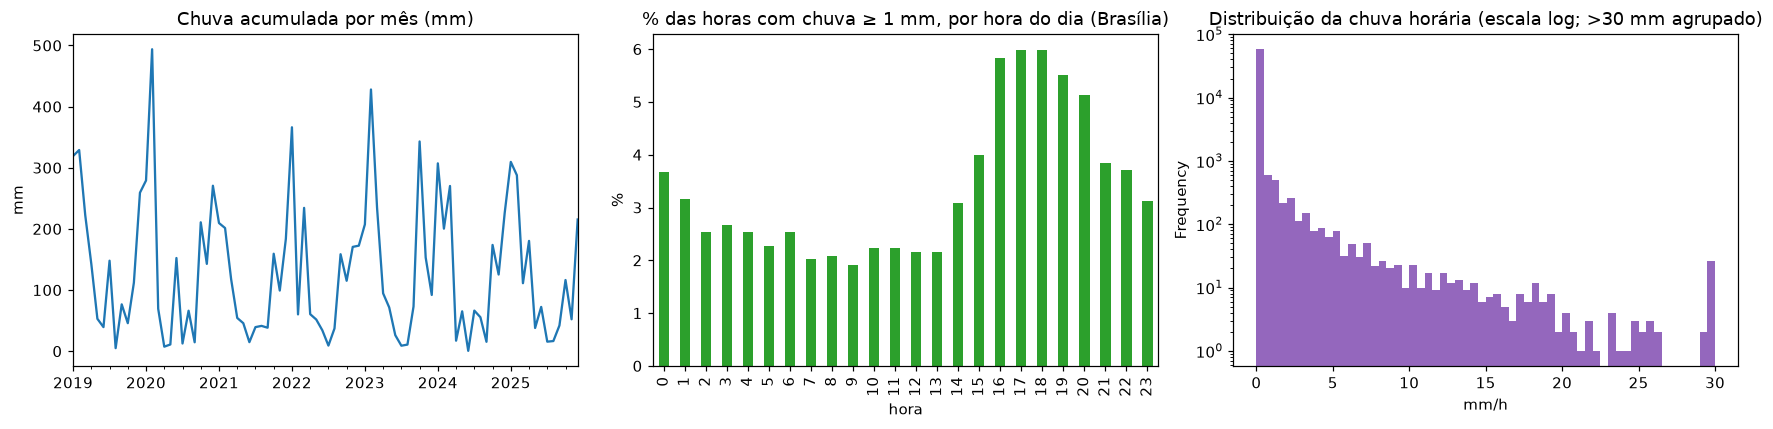

In [5]:
fig, eixos = plt.subplots(1, 3, figsize=(16, 4))

chuva_mensal = bruto["chuva_mm"].resample("MS").sum()
chuva_mensal.plot(ax=eixos[0], color="#1f77b4")
eixos[0].set(title="Chuva acumulada por mês (mm)", xlabel="", ylabel="mm")

horas_local = bruto.index.tz_convert("America/Sao_Paulo").hour
(bruto["chuva_mm"] >= 1).groupby(horas_local).mean().mul(100).plot.bar(ax=eixos[1], color="#2ca02c")
eixos[1].set(title="% das horas com chuva ≥ 1 mm, por hora do dia (Brasília)", xlabel="hora", ylabel="%")

bruto["chuva_mm"].dropna().clip(upper=30).plot.hist(bins=60, ax=eixos[2], log=True, color="#9467bd")
eixos[2].set(title="Distribuição da chuva horária (escala log; >30 mm agrupado)", xlabel="mm/h")

plt.tight_layout()
plt.savefig(SAIDA_DIR / "01_exploracao.png", bbox_inches="tight")
plt.show()

## 6. Preparação dos dados: variáveis e alvo

**Variáveis (features)** — só usam informação disponível **até a hora atual `t`**:
- medições da hora: chuva, pressão, temperatura, ponto de orvalho, umidade, vento e rajada, radiação;
- **histórico**: chuva acumulada nas últimas 3, 6, 12 e 24 h; variação de pressão, umidade e temperatura nas últimas 3 h; depressão do ponto de orvalho (temperatura − orvalho);
- **calendário**: hora do dia e mês (em seno/cosseno, para o ciclo "fechar").

**Alvo:** chuva somada nas horas `t+1`, `t+2` e `t+3` **≥ `LIMIAR_MM`**.

> **Vazamento de dados (*data leakage*):** o alvo olha para o futuro, as variáveis só para o passado. Nenhuma variável usa horas depois de `t`.

In [6]:
def montar_dataset(bruto: pd.DataFrame, horizonte: int, limiar_mm: float):
    df = bruto.copy()
    local = df.index.tz_convert("America/Sao_Paulo")

    # Radiação é vazia à noite: onde falta e é noite, o correto é 0 (não há sol).
    noite = (local.hour < 6) | (local.hour >= 19)
    df["radiacao_kj"] = df["radiacao_kj"].where(~(df["radiacao_kj"].isna() & noite), 0.0)

    # Histórico (janelas que terminam na hora atual; se faltar qualquer hora, o resultado é NaN)
    for h in (3, 6, 12, 24):
        df[f"chuva_acum_{h}h"] = df["chuva_mm"].rolling(h, min_periods=h).sum()
    df["delta_pressao_3h"] = df["pressao_hpa"] - df["pressao_hpa"].shift(3)
    df["delta_umidade_3h"] = df["umidade_pct"] - df["umidade_pct"].shift(3)
    df["delta_temp_3h"] = df["temp_c"] - df["temp_c"].shift(3)
    df["depressao_orvalho"] = df["temp_c"] - df["orvalho_c"]

    # Calendário (hora local de Brasília)
    df["hora_sin"] = np.sin(2 * np.pi * local.hour / 24)
    df["hora_cos"] = np.cos(2 * np.pi * local.hour / 24)
    df["mes_sin"] = np.sin(2 * np.pi * (local.month - 1) / 12)
    df["mes_cos"] = np.cos(2 * np.pi * (local.month - 1) / 12)

    # Alvo: chuva somada em t+1 ... t+horizonte
    futuro = pd.concat([df["chuva_mm"].shift(-k) for k in range(1, horizonte + 1)], axis=1)
    df["chuva_futura_mm"] = futuro.sum(axis=1, min_count=horizonte)
    df["alvo"] = (df["chuva_futura_mm"] >= limiar_mm).astype(float).where(df["chuva_futura_mm"].notna())

    df["ano_local"] = local.year

    candidatas = [
        "chuva_mm", "pressao_hpa", "temp_c", "orvalho_c", "umidade_pct", "vento_ms", "rajada_ms", "radiacao_kj",
        "chuva_acum_3h", "chuva_acum_6h", "chuva_acum_12h", "chuva_acum_24h",
        "delta_pressao_3h", "delta_umidade_3h", "delta_temp_3h", "depressao_orvalho",
        "hora_sin", "hora_cos", "mes_sin", "mes_cos",
    ]
    # Variáveis com mais de 40% de dados ausentes não ajudam: descartamos (e avisamos).
    descartadas = [c for c in candidatas if df[c].isna().mean() > 0.40]
    features = [c for c in candidatas if c not in descartadas]
    if descartadas:
        print("Variáveis descartadas por excesso de dados ausentes:", descartadas)

    dataset = df.dropna(subset=["alvo", "chuva_acum_24h"]).copy()
    dataset["alvo"] = dataset["alvo"].astype(int)
    return dataset, features


dataset, FEATURES = montar_dataset(bruto, HORIZONTE_H, LIMIAR_MM)

taxa = dataset["alvo"].mean() * 100
print(f"Linhas utilizáveis: {len(dataset):,}  |  horas com chuva forte à frente: {int(dataset['alvo'].sum()):,} ({taxa:.2f}%)")
print(f"Variáveis usadas ({len(FEATURES)}): {FEATURES}")
if dataset["alvo"].sum() < 150:
    print("\n⚠ Poucos eventos positivos. Considere baixar o LIMIAR_MM ou usar mais anos de dados.")

Linhas utilizáveis: 58,327  |  horas com chuva forte à frente: 952 (1.63%)
Variáveis usadas (20): ['chuva_mm', 'pressao_hpa', 'temp_c', 'orvalho_c', 'umidade_pct', 'vento_ms', 'rajada_ms', 'radiacao_kj', 'chuva_acum_3h', 'chuva_acum_6h', 'chuva_acum_12h', 'chuva_acum_24h', 'delta_pressao_3h', 'delta_umidade_3h', 'delta_temp_3h', 'depressao_orvalho', 'hora_sin', 'hora_cos', 'mes_sin', 'mes_cos']


## 7. Divisão em treino e teste

A divisão é **por tempo**, não aleatória: treinamos com os anos passados e testamos em um **ano inédito**, como seria na vida real (o modelo nunca vê o futuro).
Uma divisão aleatória misturaria horas vizinhas (que são quase iguais) entre treino e teste e daria uma nota irreal.

In [7]:
horas_por_ano = dataset.groupby("ano_local").size()
display(horas_por_ano.rename("horas utilizáveis").to_frame().T)

# Um ano é considerado completo quando tem dados nos 12 meses (assim o ano parcial mais recente não vira "teste").
meses_por_ano = (
    pd.DataFrame(
        {"ano": dataset["ano_local"].to_numpy(), "mes": dataset.index.tz_convert("America/Sao_Paulo").month}
    )
    .groupby("ano")["mes"]
    .nunique()
)
anos_completos = [int(a) for a in meses_por_ano[(meses_por_ano == 12) & (horas_por_ano >= 5000)].index]

if ANO_TESTE is None:
    if not anos_completos:
        raise ValueError("Nenhum ano completo encontrado. Baixe mais anos do INMET (veja dados/README.md).")
    ANO_TESTE = max(anos_completos)
print(f"Anos completos: {anos_completos}  ->  ano de teste: {ANO_TESTE}")

treino = dataset[dataset["ano_local"] < ANO_TESTE]
teste = dataset[dataset["ano_local"] == ANO_TESTE]

X_treino, y_treino = treino[FEATURES], treino["alvo"]
X_teste, y_teste = teste[FEATURES], teste["alvo"]

resumo_divisao = pd.DataFrame(
    {
        "período": [f"{treino.ano_local.min()}–{treino.ano_local.max()}", str(ANO_TESTE)],
        "linhas": [len(treino), len(teste)],
        "eventos (alvo=1)": [int(y_treino.sum()), int(y_teste.sum())],
        "% eventos": [round(y_treino.mean() * 100, 2), round(y_teste.mean() * 100, 2)],
    },
    index=["treino", "teste"],
)
display(resumo_divisao)

ano_local,2019,2020,2021,2022,2023,2024,2025
horas utilizáveis,8740,8730,8733,8733,7042,8452,7897


Anos completos: [2019, 2020, 2021, 2022, 2023, 2024, 2025]  ->  ano de teste: 2025


,período,linhas,eventos (alvo=1),% eventos
treino,2019–2024,50430,839,1.66
teste,2025,7897,113,1.43


## 8. Escolha do modelo: Random Forest

**Por que Random Forest?**
- Os dados são **tabulares** (medições + histórico) e a relação com a chuva é **não linear** e com interações (ex.: pressão caindo + umidade alta + chuva recente). Árvores capturam isso sem precisar de muita engenharia.
- Funciona bem com **poucos milhares de eventos** e é robusto a *outliers* e a variáveis em escalas diferentes (não precisa normalizar).
- Lida com **classe rara** com `class_weight="balanced_subsample"`.
- É **explicável**: mostra a importância de cada variável, algo importante para explicar o aviso ao cidadão.

**Por que não os outros?** Redes (MLP/LSTM) pedem mais dados e são mais difíceis de explicar; K-Means é não supervisionado e não responde "vai chover forte?".

**Hiperparâmetros testados (3):** `n_estimators` (nº de árvores), `max_depth` (profundidade máxima, controla o *overfitting*) e `min_samples_leaf` (mínimo de amostras por folha, também controla o *overfitting*).

**Validação cruzada temporal (`TimeSeriesSplit`)**: usada **somente dentro do treino**. Cada dobra treina no passado e valida no futuro imediato, com uma folga (`gap`) de 24 h para o histórico não "vazar". A métrica de seleção é a **área sob a curva Precisão–Recall (PR-AUC)**, adequada a classes raras.

In [8]:
pipeline = Pipeline(
    [
        ("imputador", SimpleImputer(strategy="median")),  # aprende a mediana só no treino
        (
            "modelo",
            RandomForestClassifier(class_weight="balanced_subsample", random_state=SEED, n_jobs=-1),
        ),
    ]
)

espaco_busca = {
    "modelo__n_estimators": [100, 200, 300],
    "modelo__max_depth": [4, 6, 8, 12, 16],
    "modelo__min_samples_leaf": [1, 5, 10, 20, 50],
}

cv_temporal = TimeSeriesSplit(n_splits=N_SPLITS, gap=24)

busca = RandomizedSearchCV(
    pipeline,
    param_distributions=espaco_busca,
    n_iter=N_ITER,
    scoring="average_precision",
    cv=cv_temporal,
    random_state=SEED,
    n_jobs=1,
    return_train_score=True,
    refit=True,
    verbose=1,
)
busca.fit(X_treino, y_treino)  # o conjunto de TESTE não é usado aqui

Fitting 5 folds for each of 12 candidates, totalling 60 fits


,"estimator estimator: estimator objectAn object of that type is instantiated for each grid point.This is assumed to implement the scikit-learn estimator interface.Either estimator needs to provide a ``score`` function,or ``scoring`` must be passed.",Pipeline(step...m_state=42))])
,"param_distributions param_distributions: dict or list of dictsDictionary with parameters names (`str`) as keys and distributionsor lists of parameters to try. Distributions must provide a ``rvs``method for sampling (such as those from scipy.stats.distributions).If a list is given, it is sampled uniformly.If a list of dicts is given, first a dict is sampled uniformly, andthen a parameter is sampled using that dict as above.","{'modelo__max_depth': [4, 6, ...], 'modelo__min_samples_leaf': [1, 5, ...], 'modelo__n_estimators': [100, 200, ...]}"
,"n_iter n_iter: int, default=10Number of parameter settings that are sampled. n_iter tradesoff runtime vs quality of the solution.",12
,"scoring scoring: str, callable, list, tuple or dict, default=NoneStrategy to evaluate the performance of the cross-validated model onthe test set.If `scoring` represents a single score, one can use:- a single string (see :ref:`scoring_string_names`);- a callable (see :ref:`scoring_callable`) that returns a single value;- `None`, the `estimator`'s :ref:`default evaluation criterion <scoring_api_overview>` is used.If `scoring` represents multiple scores, one can use:- a list or tuple of unique strings;- a callable returning a dictionary where the keys are the metric names and the values are the metric scores;- a dictionary with metric names as keys and callables as values.See :ref:`multimetric_grid_search` for an example.If None, the estimator's score method is used.",'average_precision'
,"n_jobs n_jobs: int, default=NoneNumber of jobs to run in parallel.``None`` means 1 unless in a :obj:`joblib.parallel_backend` context.``-1`` means using all processors. See :term:`Glossary <n_jobs>`for more details... versionchanged:: v0.20 `n_jobs` default changed from 1 to None",1
,"cv cv: int, cross-validation generator or an iterable, default=NoneDetermines the cross-validation splitting strategy.Possible inputs for cv are:- None, to use the default 5-fold cross validation,- integer, to specify the number of folds in a `(Stratified)KFold`,- :term:`CV splitter`,- an iterable yielding (train, test) splits as arrays of indices.For integer/None inputs, if the estimator is a classifier and ``y`` iseither binary or multiclass, :class:`StratifiedKFold` is used. In allother cases, :class:`KFold` is used. These splitters are instantiatedwith `shuffle=False` so the splits will be the same across calls.Refer :ref:`User Guide <cross_validation>` for the variouscross-validation strategies that can be used here... versionchanged:: 0.22 ``cv`` default value if None changed from 3-fold to 5-fold.",TimeSeriesSpl...est_size=None)
,"verbose verbose: int, default = 0Controls the verbosity of information printed during fitting, with highervalues yielding more detailed logging.- 0 : no messages are printed;- >=1 : summary of the total number of fits;- >=2 : computation time for each fold and parameter candidate;- >=3 : fold indices and scores;- >=10 : parameter candidate indices and START messages before each fit.",1
,"random_state random_state: int, RandomState instance or None, default=NonePseudo random number generator state used for random uniform samplingfrom lists of possible values instead of scipy.stats distributions.Pass an int for reproducible output across multiplefunction calls.See :term:`Glossary <random_state>`.",42
,"return_train_score return_train_score: bool, default=FalseIf ``False``, the ``cv_results_`` attribute will not include trainingscores.Computing training scores is used to get insights on how differentparameter settings impact the overfitting/underfitting trade-off.However computing the scores on the training set can be computationallyexpensive and is not strictly required to select t

## 9. Resultado da busca de hiperparâmetros

Cada linha é uma combinação testada. `pr_auc_treino` é a nota nas dobras de treino; `pr_auc_validacao` é a nota nas dobras de validação (dados que o modelo não viu). **Quanto maior a diferença entre as duas, maior o *overfitting*.**

,n_estimators,max_depth,min_samples_leaf,pr_auc_treino,pr_auc_validacao,desvio_validacao,ranking,gap_overfitting
0,100,16,20,0.635,0.154,0.042,1,0.481
1,100,8,50,0.385,0.154,0.045,2,0.231
2,200,6,50,0.335,0.150,0.040,3,0.185
3,100,4,50,0.274,0.134,0.034,4,0.140
4,200,4,20,0.290,0.133,0.036,5,0.157
5,100,4,1,0.290,0.126,0.025,6,0.164
6,300,8,5,0.559,0.125,0.021,7,0.434
7,200,4,5,0.291,0.125,0.027,8,0.166
8,200,8,5,0.556,0.125,0.019,9,0.431
9,200,16,5,0.949,0.123,0.021,10,0.826



Melhores hiperparâmetros: {'n_estimators': 100, 'min_samples_leaf': 20, 'max_depth': 16}
PR-AUC de validação (média das dobras): 0.154


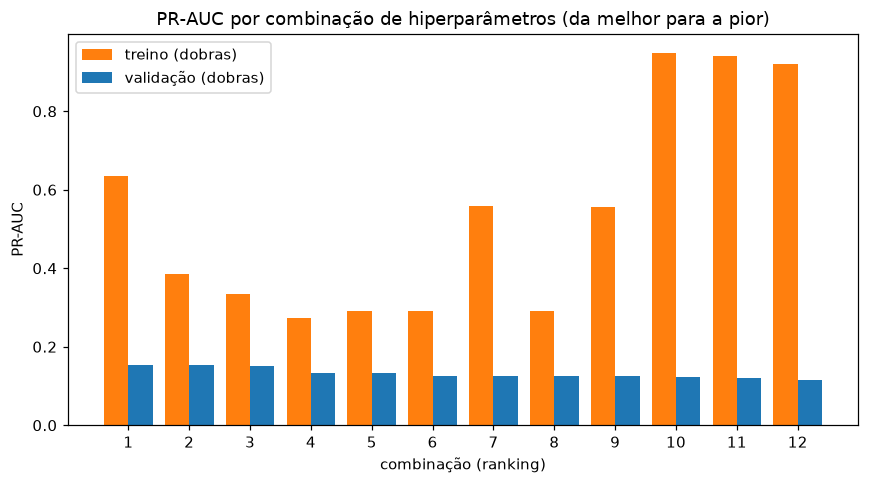

In [9]:
resultados = pd.DataFrame(busca.cv_results_)
tabela_busca = pd.DataFrame(
    {
        "n_estimators": resultados["param_modelo__n_estimators"],
        "max_depth": resultados["param_modelo__max_depth"],
        "min_samples_leaf": resultados["param_modelo__min_samples_leaf"],
        "pr_auc_treino": resultados["mean_train_score"].round(3),
        "pr_auc_validacao": resultados["mean_test_score"].round(3),
        "desvio_validacao": resultados["std_test_score"].round(3),
        "ranking": resultados["rank_test_score"],
    }
).sort_values("ranking")
tabela_busca["gap_overfitting"] = (tabela_busca["pr_auc_treino"] - tabela_busca["pr_auc_validacao"]).round(3)
display(tabela_busca.reset_index(drop=True))
tabela_busca.to_csv(SAIDA_DIR / "busca_hiperparametros.csv", index=False)

print("\nMelhores hiperparâmetros:", {k.replace("modelo__", ""): v for k, v in busca.best_params_.items()})
print(f"PR-AUC de validação (média das dobras): {busca.best_score_:.3f}")

fig, eixo = plt.subplots(figsize=(8, 4.5))
ordenado = tabela_busca.sort_values("ranking")
posicoes = np.arange(len(ordenado))
eixo.bar(posicoes - 0.2, ordenado["pr_auc_treino"], width=0.4, label="treino (dobras)", color="#ff7f0e")
eixo.bar(posicoes + 0.2, ordenado["pr_auc_validacao"], width=0.4, label="validação (dobras)", color="#1f77b4")
eixo.set(title="PR-AUC por combinação de hiperparâmetros (da melhor para a pior)", xlabel="combinação (ranking)", ylabel="PR-AUC")
eixo.set_xticks(posicoes)
eixo.set_xticklabels(ordenado["ranking"].astype(int))
eixo.legend()
plt.tight_layout()
plt.savefig(SAIDA_DIR / "02_busca_hiperparametros.png", bbox_inches="tight")
plt.show()

## 10. Limiar de decisão

O modelo devolve uma **probabilidade**. Para virar "aviso" precisamos de um corte. Como **deixar de avisar uma chuva forte é pior do que um alarme falso**, escolhemos o corte que maximiza o **F2** (dá mais peso ao *recall* do que à precisão).
O corte é escolhido com as previsões **fora da amostra das dobras de validação do treino** – o teste continua intocado.

In [10]:
prob_val, y_val = [], []
for idx_treino, idx_val in cv_temporal.split(X_treino):
    modelo_dobra = clone(busca.best_estimator_)
    modelo_dobra.fit(X_treino.iloc[idx_treino], y_treino.iloc[idx_treino])
    prob_val.append(modelo_dobra.predict_proba(X_treino.iloc[idx_val])[:, 1])
    y_val.append(y_treino.iloc[idx_val].to_numpy())

prob_val = np.concatenate(prob_val)
y_val = np.concatenate(y_val)

precisoes, recalls, cortes = precision_recall_curve(y_val, prob_val)
with np.errstate(divide="ignore", invalid="ignore"):
    f2 = np.where((4 * precisoes + recalls) > 0, 5 * precisoes * recalls / (4 * precisoes + recalls), 0.0)
LIMIAR_DECISAO = float(cortes[int(np.argmax(f2[:-1]))])
print(f"Limiar de decisão escolhido (F2 máximo nas dobras de validação): {LIMIAR_DECISAO:.3f}")

Limiar de decisão escolhido (F2 máximo nas dobras de validação): 0.423


## 11. Resultados: treino × validação × teste

Comparamos o modelo com **dois pontos de referência**:
- *Sorteio pela proporção* (`DummyClassifier`): ignora as variáveis e só conhece a frequência de chuva forte;
- *Regra simples*: "se choveu ≥ 1 mm nas últimas 3 h, avise".

In [11]:
def calcular_metricas(y_real, probabilidade, corte):
    previsto = (np.asarray(probabilidade) >= corte).astype(int)
    try:
        roc = roc_auc_score(y_real, probabilidade)
    except ValueError:
        roc = np.nan
    return {
        "precisão": precision_score(y_real, previsto, zero_division=0),
        "recall": recall_score(y_real, previsto, zero_division=0),
        "F1": f1_score(y_real, previsto, zero_division=0),
        "F2": fbeta_score(y_real, previsto, beta=2, zero_division=0),
        "PR-AUC": average_precision_score(y_real, probabilidade),
        "ROC-AUC": roc,
    }


modelo_final = busca.best_estimator_  # já treinado com TODO o treino (refit=True)
prob_treino = modelo_final.predict_proba(X_treino)[:, 1]
prob_teste = modelo_final.predict_proba(X_teste)[:, 1]

dummy = DummyClassifier(strategy="prior").fit(X_treino, y_treino)
prob_dummy = dummy.predict_proba(X_teste)[:, 1]
prob_regra = X_teste["chuva_acum_3h"].to_numpy()

linhas = {
    "Random Forest – treino (dentro da amostra)": calcular_metricas(y_treino, prob_treino, LIMIAR_DECISAO),
    "Random Forest – TESTE": calcular_metricas(y_teste, prob_teste, LIMIAR_DECISAO),
    "Referência: sorteio pela proporção – teste": calcular_metricas(y_teste, prob_dummy, 0.5),
    "Referência: regra 'choveu ≥ 1 mm em 3 h' – teste": calcular_metricas(y_teste, prob_regra, 1.0),
}
tabela_resultados = pd.DataFrame(linhas).T.round(3)

# Linha extra: a nota da validação cruzada (PR-AUC) vem da busca, sem tocar no teste.
tabela_resultados.loc["Random Forest – validação cruzada (PR-AUC)", "PR-AUC"] = round(busca.best_score_, 3)
display(tabela_resultados)
tabela_resultados.to_csv(SAIDA_DIR / "metricas.csv")

matriz = confusion_matrix(y_teste, (prob_teste >= LIMIAR_DECISAO).astype(int), labels=[0, 1])
tn, fp, fn, tp = matriz.ravel()
print(f"\nMatriz de confusão no TESTE (corte {LIMIAR_DECISAO:.3f}):")
print(f"  verdadeiros negativos: {tn:,} | falsos positivos (alarmes falsos): {fp:,}")
print(f"  falsos negativos (chuva forte NÃO avisada): {fn:,} | verdadeiros positivos (avisos certos): {tp:,}")

,precisão,recall,F1,F2,PR-AUC,ROC-AUC
Random Forest – treino (dentro da amostra),0.225,0.999,0.368,0.592,0.615,0.991
Random Forest – TESTE,0.120,0.531,0.196,0.316,0.156,0.901
Referência: sorteio pela proporção – teste,0.000,0.000,0.000,0.000,0.014,0.500
Referência: regra 'choveu ≥ 1 mm em 3 h' – teste,0.101,0.425,0.163,0.258,0.084,0.731
Random Forest – validação cruzada (PR-AUC),NaN,NaN,NaN,NaN,0.154,NaN



Matriz de confusão no TESTE (corte 0.423):
  verdadeiros negativos: 7,346 | falsos positivos (alarmes falsos): 438
  falsos negativos (chuva forte NÃO avisada): 53 | verdadeiros positivos (avisos certos): 60


### 11.1 Gráficos

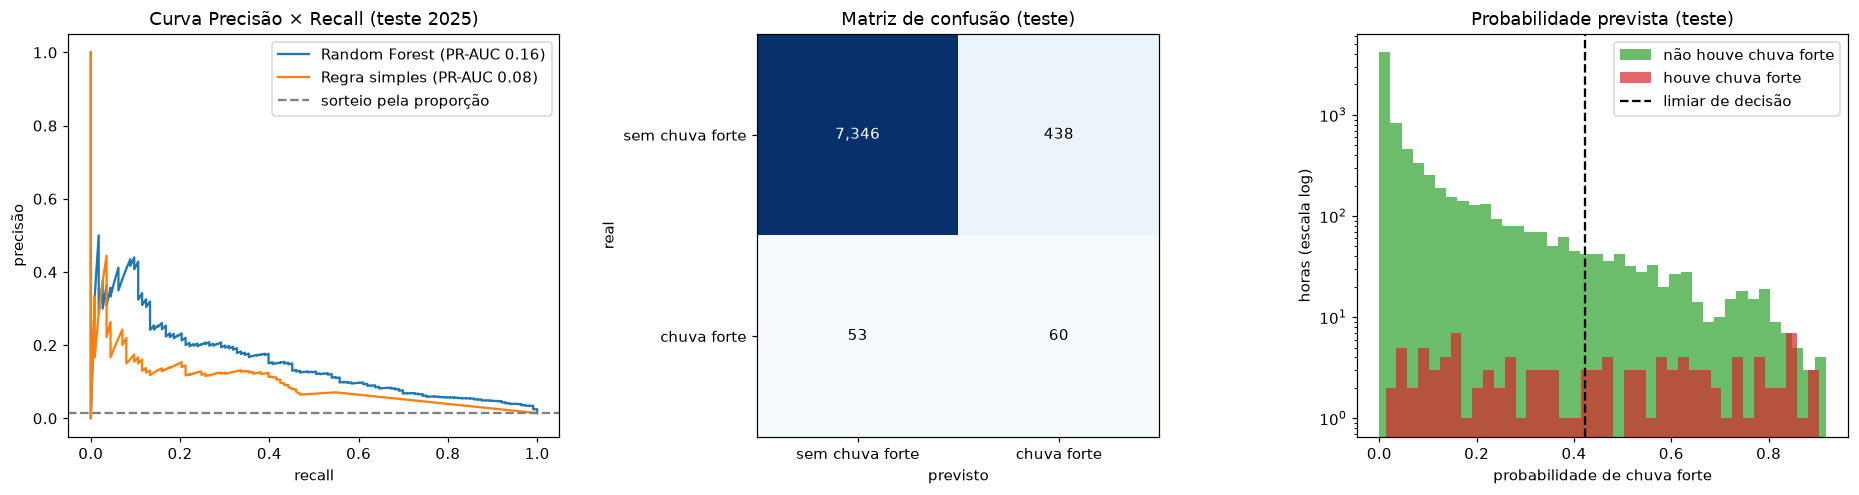

In [12]:
fig, eixos = plt.subplots(1, 3, figsize=(17, 4.6))

# Curva Precisão-Recall
p_t, r_t, _ = precision_recall_curve(y_teste, prob_teste)
p_r, r_r, _ = precision_recall_curve(y_teste, prob_regra)
eixos[0].plot(r_t, p_t, label=f"Random Forest (PR-AUC {average_precision_score(y_teste, prob_teste):.2f})", color="#1f77b4")
eixos[0].plot(r_r, p_r, label=f"Regra simples (PR-AUC {average_precision_score(y_teste, prob_regra):.2f})", color="#ff7f0e")
eixos[0].axhline(y_teste.mean(), color="gray", ls="--", label="sorteio pela proporção")
eixos[0].set(title=f"Curva Precisão × Recall (teste {ANO_TESTE})", xlabel="recall", ylabel="precisão")
eixos[0].legend(loc="upper right")

# Matriz de confusão
eixos[1].imshow(matriz, cmap="Blues")
for (i, j), valor in np.ndenumerate(matriz):
    eixos[1].text(j, i, f"{valor:,}", ha="center", va="center", color="black" if valor < matriz.max() / 2 else "white")
eixos[1].set(title="Matriz de confusão (teste)", xticks=[0, 1], yticks=[0, 1], xlabel="previsto", ylabel="real")
eixos[1].set_xticklabels(["sem chuva forte", "chuva forte"])
eixos[1].set_yticklabels(["sem chuva forte", "chuva forte"])

# Distribuição das probabilidades
eixos[2].hist(prob_teste[y_teste.to_numpy() == 0], bins=40, alpha=0.7, label="não houve chuva forte", color="#2ca02c", log=True)
eixos[2].hist(prob_teste[y_teste.to_numpy() == 1], bins=40, alpha=0.7, label="houve chuva forte", color="#d62728", log=True)
eixos[2].axvline(LIMIAR_DECISAO, color="black", ls="--", label="limiar de decisão")
eixos[2].set(title="Probabilidade prevista (teste)", xlabel="probabilidade de chuva forte", ylabel="horas (escala log)")
eixos[2].legend()

plt.tight_layout()
plt.savefig(SAIDA_DIR / "03_resultados_teste.png", bbox_inches="tight")
plt.show()

### 11.2 O que o modelo aprendeu: importância das variáveis

Usamos a **importância por permutação** no teste: embaralhamos uma variável e vemos quanto a PR-AUC piora. Quanto mais piora, mais o modelo depende dela.

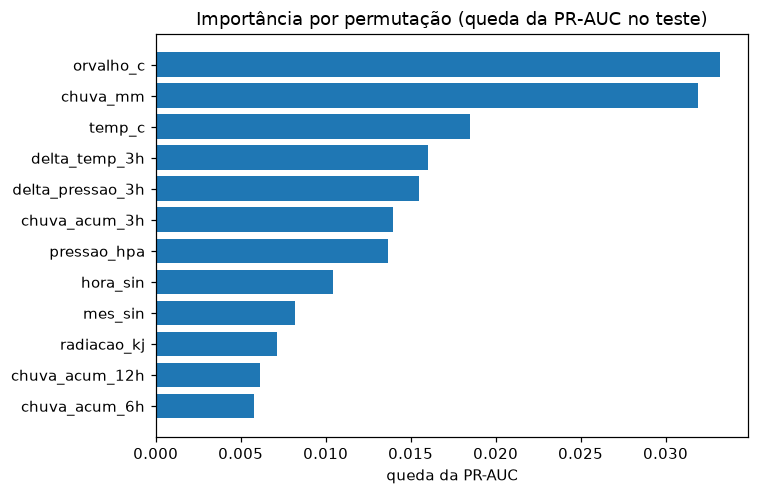

In [13]:
importancia = permutation_importance(
    modelo_final, X_teste, y_teste, scoring="average_precision", n_repeats=5, random_state=SEED, n_jobs=1
)
tabela_importancia = (
    pd.DataFrame({"variavel": FEATURES, "queda_pr_auc": importancia.importances_mean})
    .sort_values("queda_pr_auc", ascending=True)
    .tail(12)
)

fig, eixo = plt.subplots(figsize=(7, 4.6))
eixo.barh(tabela_importancia["variavel"], tabela_importancia["queda_pr_auc"], color="#1f77b4")
eixo.set(title="Importância por permutação (queda da PR-AUC no teste)", xlabel="queda da PR-AUC")
plt.tight_layout()
plt.savefig(SAIDA_DIR / "04_importancia_variaveis.png", bbox_inches="tight")
plt.show()

## 12. Overfitting: o modelo decorou ou aprendeu?

Três notas, três significados:
- **Treino (dentro da amostra):** o modelo já viu esses dados. Em Random Forest costuma ser muito alta e **não mede qualidade**.
- **Validação cruzada (dentro do treino):** simula o futuro dentro do período de treino.
- **Teste (ano inédito):** a nota que importa.

In [14]:
melhor = busca.best_index_
pr_treino_cv = float(busca.cv_results_["mean_train_score"][melhor])
pr_val = float(busca.best_score_)
pr_teste = float(tabela_resultados.loc["Random Forest – TESTE", "PR-AUC"])
pr_treino_total = float(tabela_resultados.loc["Random Forest – treino (dentro da amostra)", "PR-AUC"])

print(f"PR-AUC no treino, dentro da amostra (todo o treino):  {pr_treino_total:.3f}")
print(f"PR-AUC no treino das dobras da validação cruzada:     {pr_treino_cv:.3f}")
print(f"PR-AUC na validação cruzada (dados não vistos):       {pr_val:.3f}")
print(f"PR-AUC no TESTE (ano inédito {ANO_TESTE}):                  {pr_teste:.3f}")

gap_cv = pr_treino_cv - pr_val
print(f"\nDiferença treino − validação (melhor combinação): {gap_cv:.3f}")
print(f"Diferença validação − teste: {pr_val - pr_teste:.3f}")

if gap_cv > 0.25:
    print("→ O modelo acerta bem mais nos dados em que treinou do que em dados novos: há overfitting "
          "(comum em Random Forest). max_depth e min_samples_leaf servem para reduzi-lo.")
else:
    print("→ A diferença entre treino e validação é moderada: o overfitting está sob controle.")

if abs(pr_val - pr_teste) <= 0.10:
    print("→ A nota da validação cruzada previu bem a nota no ano inédito: o processo de seleção é confiável.")
else:
    print("→ A nota do teste difere da validação: chuva forte é rara e varia de ano para ano, então desconfie de "
          "diferenças pequenas e comente isso no relatório.")

PR-AUC no treino, dentro da amostra (todo o treino):  0.615
PR-AUC no treino das dobras da validação cruzada:     0.635
PR-AUC na validação cruzada (dados não vistos):       0.154
PR-AUC no TESTE (ano inédito 2025):                  0.156

Diferença treino − validação (melhor combinação): 0.481
Diferença validação − teste: -0.002
→ O modelo acerta bem mais nos dados em que treinou do que em dados novos: há overfitting (comum em Random Forest). max_depth e min_samples_leaf servem para reduzi-lo.
→ A nota da validação cruzada previu bem a nota no ano inédito: o processo de seleção é confiável.


> **Para o relatório:** comentem (1) o tamanho da diferença treino × validação × teste; (2) quais hiperparâmetros mais controlaram o overfitting (olhem a coluna `gap_overfitting` da tabela da seção 9: árvores mais rasas e folhas maiores tendem a diminuir o gap); (3) por que o teste é de um ano inédito.

## 13. Leitura para o cidadão

Os números abaixo traduzem as métricas para a vida real, no ano de teste. Um **episódio** é um conjunto de horas de chuva forte separadas por menos de 6 h.

In [15]:
def agrupar_episodios(mascara: pd.Series, folga_horas: int = 6):
    instantes = mascara.index[mascara.to_numpy()]
    if len(instantes) == 0:
        return []
    episodios, inicio, fim = [], instantes[0], instantes[0]
    for instante in instantes[1:]:
        if instante - fim <= pd.Timedelta(hours=folga_horas):
            fim = instante
        else:
            episodios.append((inicio, fim))
            inicio = fim = instante
    episodios.append((inicio, fim))
    return episodios


previsto_teste = pd.Series((prob_teste >= LIMIAR_DECISAO), index=y_teste.index)
episodios_reais = agrupar_episodios(y_teste == 1)
episodios_alerta = agrupar_episodios(previsto_teste)

detectados = sum(1 for ini, fim in episodios_reais if previsto_teste.loc[ini:fim].any())
alertas_certos = sum(1 for ini, fim in episodios_alerta if (y_teste.loc[ini:fim] == 1).any())
alertas_falsos = len(episodios_alerta) - alertas_certos
meses_teste = max(1, teste.index.tz_convert("America/Sao_Paulo").tz_localize(None).to_period("M").nunique())

print(f"Ano de teste: {ANO_TESTE}")
print(f"Episódios reais de chuva forte: {len(episodios_reais)}")
print(f"  avisados pelo modelo: {detectados} ({detectados / max(1, len(episodios_reais)):.0%})")
print(f"  sem aviso: {len(episodios_reais) - detectados}")
print(f"Episódios de alerta emitidos: {len(episodios_alerta)}")
print(f"  confirmados por chuva forte: {alertas_certos}")
print(f"  alarmes falsos: {alertas_falsos} (≈ {alertas_falsos / meses_teste:.1f} por mês)")

metricas_cidadao = {
    "ano_teste": ANO_TESTE,
    "episodios_reais": len(episodios_reais),
    "episodios_avisados": int(detectados),
    "episodios_alerta": len(episodios_alerta),
    "alarmes_falsos": int(alertas_falsos),
    "alarmes_falsos_por_mes": round(alertas_falsos / meses_teste, 2),
}

Ano de teste: 2025
Episódios reais de chuva forte: 34
  avisados pelo modelo: 23 (68%)
  sem aviso: 11
Episódios de alerta emitidos: 118
  confirmados por chuva forte: 27
  alarmes falsos: 91 (≈ 7.6 por mês)


### O que isso significa para o morador do Ipiranga?

_[PREENCHER com os números acima, em linguagem simples. Exemplo de estrutura:]_

- De cada **N** episódios de chuva forte no ano de teste, o modelo avisou **X**. Os outros **Y** passaram sem aviso, e por isso o sensor de nível continua sendo a segunda camada de proteção.
- Foram emitidos **Z** alertas; **W** foram alarmes falsos (cerca de **K por mês**). Alarmes demais fazem as pessoas ignorarem o aviso, então o limiar é um equilíbrio.
- O modelo olha **3 horas à frente**: é um aviso para **se preparar** (guardar objetos, combinar ajuda com vizinhos, evitar sair), não uma previsão exata do bairro.

### Limitações (seja honesto no relatório)
- A estação **A701 fica na zona norte**, não no Ipiranga: a chuva pode ser diferente no bairro.
- Dados **horários**: tempestades muito rápidas podem passar entre duas medições.
- Poucos eventos extremos no ano de teste: os números podem variar bastante de um ano para outro.
- O modelo prevê **chuva forte**, não **alagamento** (que depende também da drenagem, do rio e do solo).

### Próximos passos
- Usar a probabilidade do modelo como **reforço** do risco na API de monitoramento (C#).
- Testar outras estações e mais anos; comparar com XGBoost.

## 14. Salvando o modelo e exemplo de uso

O modelo fica salvo em `modelo/modelo_chuva_forte.joblib` junto com a lista de variáveis e o limiar de decisão, pronto para ser usado em um serviço.

In [16]:
joblib.dump(
    {
        "pipeline": modelo_final,
        "features": FEATURES,
        "limiar_decisao": LIMIAR_DECISAO,
        "horizonte_h": HORIZONTE_H,
        "limiar_mm": LIMIAR_MM,
        "estacao": ESTACAO,
    },
    MODELO_DIR / "modelo_chuva_forte.joblib",
)

pacote = joblib.load(MODELO_DIR / "modelo_chuva_forte.joblib")
ultima_hora = X_teste.tail(1)
probabilidade = float(pacote["pipeline"].predict_proba(ultima_hora[pacote["features"]])[0, 1])
situacao = "ALERTA de chuva forte nas próximas horas" if probabilidade >= pacote["limiar_decisao"] else "sem alerta"
print(f"Hora analisada: {ultima_hora.index[0]}")
print(f"Probabilidade de chuva forte nas próximas {pacote['horizonte_h']} h: {probabilidade:.1%} -> {situacao}")

resumo_final = {
    "estacao": ESTACAO,
    "periodo_treino": f"{treino.ano_local.min()}-{treino.ano_local.max()}",
    "ano_teste": ANO_TESTE,
    "horizonte_h": HORIZONTE_H,
    "limiar_mm": LIMIAR_MM,
    "limiar_decisao": round(LIMIAR_DECISAO, 4),
    "melhores_hiperparametros": {k.replace("modelo__", ""): (None if v is None else int(v)) for k, v in busca.best_params_.items()},
    "metricas_teste": {k: (None if pd.isna(v) else round(float(v), 4)) for k, v in tabela_resultados.loc["Random Forest – TESTE"].items()},
    "leitura_cidadao": metricas_cidadao,
}
(SAIDA_DIR / "resumo.json").write_text(json.dumps(resumo_final, ensure_ascii=False, indent=2), encoding="utf-8")
print("\nArquivos gerados em 'resultados/' e 'modelo/'.")

Hora analisada: 2025-12-31 20:00:00+00:00
Probabilidade de chuva forte nas próximas 3 h: 71.5% -> ALERTA de chuva forte nas próximas horas

Arquivos gerados em 'resultados/' e 'modelo/'.


## 15. Referências e uso de IA

- INMET – Dados Históricos: https://portal.inmet.gov.br/dadoshistoricos (estação A701, São Paulo – Mirante de Santana).
- scikit-learn: `RandomForestClassifier`, `RandomizedSearchCV`, `TimeSeriesSplit`, `precision_recall_curve`.
- Uso de IA como copiloto: os prompts estão registrados em `prompts.md` (na raiz do repositório). **Cada integrante deve saber explicar cada célula deste notebook.**